In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
#import the training data 
df= pd.read_csv('exported training data.csv')

In [3]:
data=df.drop({'system:index','.geo'} ,axis=1)

In [4]:
data

,B2,B3,B4,B8,EVI,GNDVI,NBR,NDUI,NDVI,NDWI,class
0,1833.0,2188.0,2397.0,2886.0,0.347153,0.137564,-0.060394,-0.597946,0.092561,-0.093166,0
1,839.0,942.0,617.5,285.5,0.360713,-0.534827,0.406404,-1.053081,-0.367663,0.213603,0
2,811.0,966.5,597.0,199.0,0.432515,-0.658516,0.285945,-1.048685,-0.500000,0.104022,0
3,1030.5,1272.0,1341.0,1404.5,0.092149,0.049505,0.168226,-0.163309,0.023129,0.091510,0
4,2158.0,2617.0,2920.0,3077.5,0.089215,0.080868,-0.011801,-0.124709,0.026261,-0.063522,0
...,...,...,...,...,...,...,...,...,...,...,...
852,611.5,834.0,965.5,1907.5,0.755959,0.391574,-0.120664,-0.921990,0.327880,-0.186654,4
853,729.5,1000.0,1231.0,1975.0,0.478057,0.327731,-0.047963,-0.739873,0.232065,-0.136329,4
854,685.0,967.5,1102.0,2234.0,0.762906,0.395596,-0.051883,-0.800743,0.339329,-0.125379,4
855,784.0,1046.5,1173.0,2096.0,0.708909,0.333970,-0.015962,-0.876790,0.282349,-0.119698,4


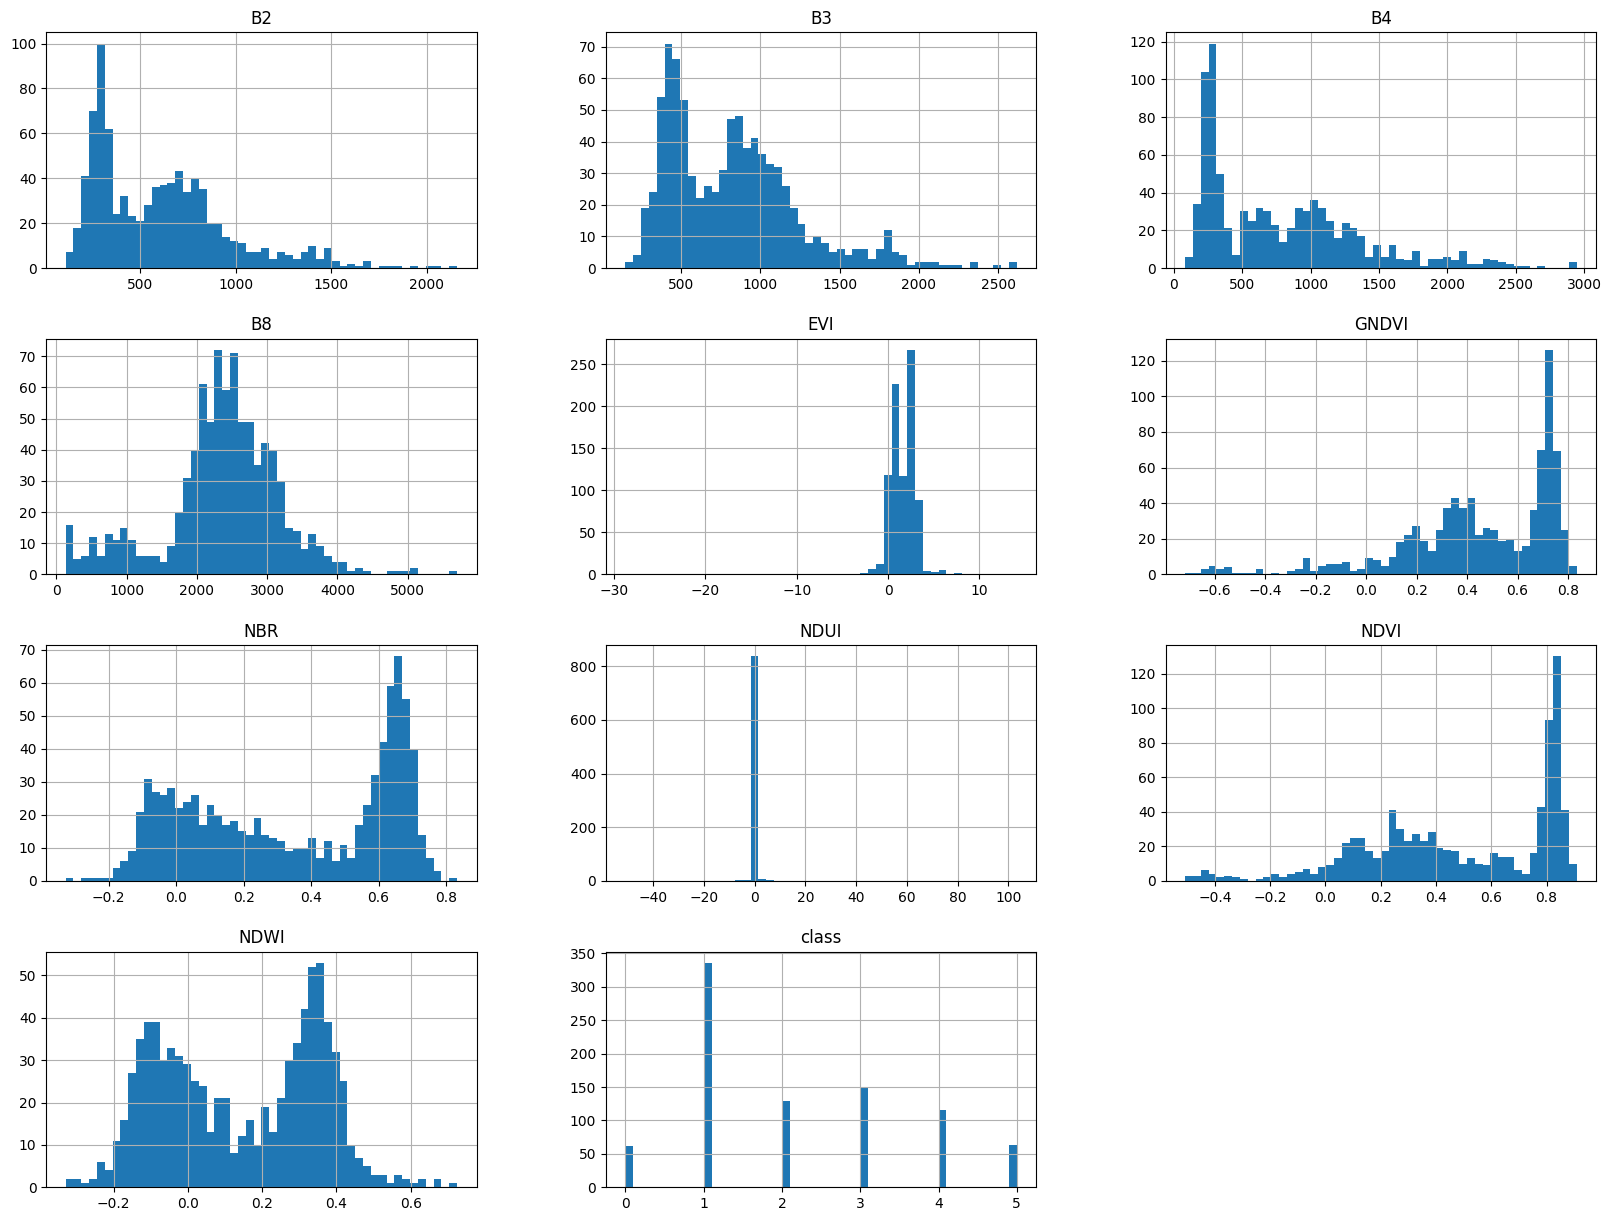

In [5]:
data.hist(bins=50, figsize=(20,15))
plt.show()

In [6]:
class1= data['class'].value_counts()
class1

class
1    336
3    150
2    129
4    116
5     64
0     62
Name: count, dtype: int64

In [7]:
#using stratified test train split for better split of data form class to find better accuracy
from sklearn.model_selection import StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=42)
for train_index, test_index in split.split(data, data["class"]):
     train_set = data.loc[train_index]
     test_set = data.loc[test_index]

In [8]:
test_set["class"].value_counts() / len(test_set)

class
1    0.389535
3    0.174419
2    0.151163
4    0.133721
0    0.075581
5    0.075581
Name: count, dtype: float64

In [9]:
data= train_set.copy()

In [11]:
corr_matrix = data.corr()
corr_matrix["class"].sort_values(ascending=False)

class    1.000000
B4       0.359660
B3       0.294400
B2       0.269574
NDUI     0.010440
B8      -0.083373
GNDVI   -0.209573
NDVI    -0.313126
EVI     -0.340186
NDWI    -0.507403
NBR     -0.512295
Name: class, dtype: float64

In [14]:
data=train_set.drop('class',axis=1)
data_label= train_set['class']

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
full_pipeline = Pipeline([
 ('std_scaler', StandardScaler()),
 ])


In [16]:
data_prepared = full_pipeline.fit_transform(data)

In [19]:
from sklearn.linear_model import SGDClassifier
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(data_prepared, data_label)

,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


In [23]:
some_data=data_prepared[:5]
some_lable=data_label[:5]

In [24]:
sgd_clf.predict(some_data)

array([4, 1, 1, 2, 4])

In [25]:
some_lable

35     0
672    3
349    1
494    2
797    4
Name: class, dtype: int64

In [28]:
from sklearn.model_selection import cross_val_score
cross_val_score(sgd_clf, data_prepared, data_label, cv=3, scoring="accuracy")

array([0.80786026, 0.76315789, 0.72368421])

In [39]:
xtest=test_set.drop('class',axis=1)
ytest= test_set['class']
xtest = full_pipeline.fit_transform(xtest)

In [40]:
from sklearn.metrics import accuracy_score
y_pred = sgd_clf.predict(xtest)
accuracy_score(ytest, y_pred)

0.8081395348837209

In [33]:
from sklearn.model_selection import cross_val_predict
data_label_pred = cross_val_predict(sgd_clf, data_prepared, data_label, cv=3)
from sklearn.metrics import confusion_matrix
confusion_matrix(data_label,data_label_pred)

array([[ 12,   0,   6,  15,   5,  11],
       [  0, 259,   4,   4,   1,   1],
       [  4,   1,  75,  12,   8,   3],
       [  1,   2,   4,  85,  12,  16],
       [  0,   2,   4,   1,  70,  16],
       [  3,   0,   6,   5,  14,  23]])

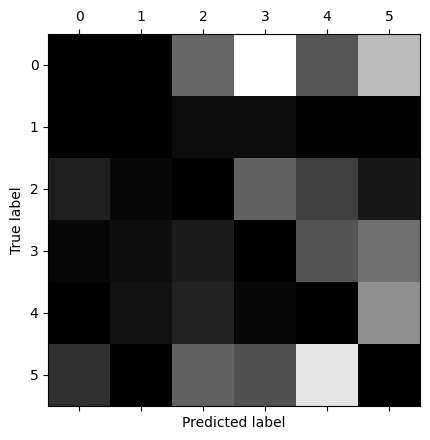

In [34]:
import matplotlib.pyplot as plt

conf_mx = confusion_matrix(data_label, data_label_pred)

# Normalize by row (divide each row by its sum, i.e. by the true class count)
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums

# Zero out the diagonal so only errors stand out visually
norm_conf_mx_errors = norm_conf_mx.copy()
np.fill_diagonal(norm_conf_mx_errors, 0)

plt.matshow(norm_conf_mx_errors, cmap=plt.cm.gray)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

In [85]:
from sklearn.ensemble import RandomForestClassifier
forest_clf = RandomForestClassifier(n_estimators=50,max_leaf_nodes=16,bootstrap=False,random_state=42)
forest_clf.fit(data_prepared, data_label)

,n_estimators,50
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,16
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [86]:
from sklearn.metrics import accuracy_score
y_pred = forest_clf.predict(xtest)
accuracy_score(ytest, y_pred)

0.7790697674418605